# Lab 4: Regularization

## Exercise: Regularization of German Credit Numeric example

* Vamos a aplicar las siguientes regularizaciones al ejemplo _German Credit_
  - _Early stopping_
  - Regularización de pesos
  - _Dropout_

### Cargamos el conjunto de datos

In [2]:
import keras
from keras import layers
import tensorflow as tf
import tensorflow_datasets as tfds
import os
import numpy as np
import random

#Fijamos la semilla para poder reproducir los resultados
seed=1234
os.environ['PYTHONHASHSEED']=str(seed)
tf.random.set_seed(seed)
np.random.seed(seed)
random.seed(seed)

In [3]:
# Cargamos el conjunto de datos
ds_train = tfds.load('german_credit_numeric', split='train[:40%]',  as_supervised=True).batch(128)
ds_val = tfds.load('german_credit_numeric', split='train[40%:50%]', as_supervised=True).batch(128)
ds_test = tfds.load('german_credit_numeric', split='train[50%:]', as_supervised=True).batch(128)

I0000 00:00:1793809140.220068  513231 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3895 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 2060, pci bus id: 0000:08:00.0, compute capability: 7.5


In [4]:
#Indicamos la función de perdida, el algoritmo de optimización y la métrica para evaluar el rendimiento 
fn_perdida = keras.losses.BinaryCrossentropy()
optimizador = keras.optimizers.Adam(0.001)
metrica = keras.metrics.AUC()

### Creamos un modelo `Sequential`

In [5]:
tamano_entrada = 24
h0_size = 20
h1_size = 10
h2_size = 5

model =  keras.Sequential(name="german_credit_base")

model.add(layers.Input(shape=(tamano_entrada,)))
model.add(layers.Dense(h0_size, activation="relu"))
model.add(layers.Dense(h1_size, activation="relu"))
model.add(layers.Dense(h2_size, activation="relu"))
model.add(layers.Dense(1, activation="sigmoid"))

#Construimos el modelo y mostramos 
model.build()
print(model.summary())

Model: "german_credit_base"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 20)             │           500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           210 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │            55 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │             6 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 771 (3.01 KB)

 Trainable params: 771 (3.01 KB)

 Non-trainable params: 0 (0.00 B)

None


In [6]:
model.compile(loss=fn_perdida,
              optimizer=optimizador,
              metrics=[metrica])

In [7]:
#Establecemos el número de epochs
num_epochs =  700

# Guardamos los pesos antes de entrenar, para poder resetear el modelo posteriormente y hacer comparativas.
pesos_preentrenamiento = model.get_weights()

history = model.fit(ds_train, epochs=num_epochs, validation_data=ds_val)

Epoch 1/700


/home/acrafto/miniconda3/envs/ap-dl/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1793809143.987360  513374 tf_record_dataset_op.cc:396] The default buffer size is 262144, which is overridden by the user specified `buffer_size` of 8388608
I0000 00:00:1793809143.994162  513320 service.cc:153] XLA service 0x7371b80325f0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793809143.994210  513320 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 2060, Compute Capability 7.5 (Driver: 13.3.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1793809144.058248  513320 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPR

1/4 ━━━━━━━━━━━━━━━━━━━━ 8s 3s/step - auc: 0.4138 - loss: 2.8588

I0000 00:00:1793809145.734786  513320 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.
I0000 00:00:1793809146.018112  513322 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1959__.15


4/4 ━━━━━━━━━━━━━━━━━━━━ 5s 770ms/step - auc: 0.4124 - loss: 2.7260 - val_auc: 0.2993 - val_loss: 2.7839
Epoch 2/700
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - auc: 0.3984 - loss: 2.0982 - val_auc: 0.2821 - val_loss: 2.1012
Epoch 3/700
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - auc: 0.3913 - loss: 1.5754 - val_auc: 0.3131 - val_loss: 1.5344
Epoch 4/700
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - auc: 0.3845 - loss: 1.1788 - val_auc: 0.3129 - val_loss: 1.1670
Epoch 5/700
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - auc: 0.3842 - loss: 0.9233 - val_auc: 0.3262 - val_loss: 0.9265
Epoch 6/700
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - auc: 0.3843 - loss: 0.7886 - val_auc: 0.3350 - val_loss: 0.8392
Epoch 7/700
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - auc: 0.3877 - loss: 0.7303 - val_auc: 0.3431 - val_loss: 0.7870
Epoch 8/700
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - auc: 0.4013 - loss: 0.6978 - val_auc: 0.3757 - val_loss: 0.7494
Epoch 9/700
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - auc: 0.4323 - loss: 0.6803 - va

In [8]:
import matplotlib.pyplot as plt

# Nueva versión que imprime la gráfica sin puntos
# Si son muchos (700) una recta se ve de forma más clara
def plot_no_dots(train, validation, title):
    plt.clf()
    epochs = range(1, len(train) + 1)
    
    plt.plot(epochs, train, 'b-', label='Training ' + title)
    plt.plot(epochs, validation, 'r--', label='Validation '+ title) 

    plt.title('Training and validation ' + title)
    plt.xlabel('Epochs')
    plt.ylabel(title)
    plt.legend()
    plt.show()

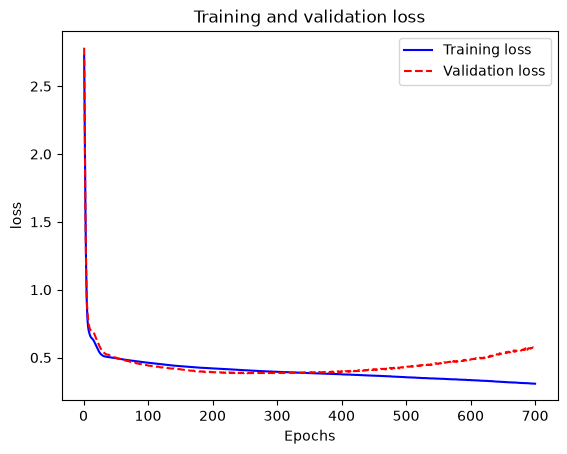

In [9]:
plot_no_dots(history.history['loss'], history.history['val_loss'], 'loss')

In [10]:
result = model.evaluate(ds_test) 
print(model.metrics_names)
print(result)

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 292ms/step - auc: 0.7241 - loss: 0.8411
['loss', 'compile_metrics']
[0.8410961627960205, 0.7241215109825134]


### 4.7.3. Usamos _Early Stopping_

In [11]:
from keras.callbacks import EarlyStopping

# simple early stopping
es = EarlyStopping(
    monitor='val_loss',#Se monitoriza la perdida(loss) del test
    mode='min',
    patience=30
)

# Antes de entrenar, olvidamos el entrenamiento anterior restaurando los pesos iniciales
model.set_weights(pesos_preentrenamiento)

history = model.fit(ds_train, epochs=num_epochs, validation_data=ds_val, callbacks=[es])

Epoch 1/700
1/4 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - auc: 0.4138 - loss: 2.8588

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - auc: 0.4110 - loss: 2.5841 - val_auc: 0.2905 - val_loss: 1.7382
Epoch 2/700
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - auc: 0.4053 - loss: 1.0893 - val_auc: 0.3069 - val_loss: 0.8402
Epoch 3/700
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - auc: 0.3759 - loss: 0.7485 - val_auc: 0.3074 - val_loss: 0.7976
Epoch 4/700
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - auc: 0.3439 - loss: 0.7648 - val_auc: 0.3771 - val_loss: 0.7535
Epoch 5/700
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - auc: 0.3869 - loss: 0.7356 - val_auc: 0.4052 - val_loss: 0.7120
Epoch 6/700
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - auc: 0.4812 - loss: 0.7022 - val_auc: 0.4733 - val_loss: 0.6907
Epoch 7/700
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - auc: 0.5072 - loss: 0.6863 - val_auc: 0.5060 - val_loss: 0.6834
Epoch 8/700
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - auc: 0.5113 - loss: 0.6796 - val_auc: 0.5000 - val_loss: 0.6803
Epoch 9/700
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - auc: 0.5244 - loss: 0.6763 - val

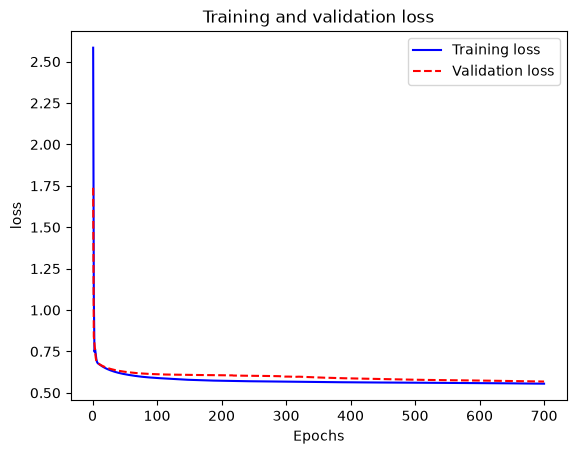

In [12]:
plot_no_dots(history.history['loss'], history.history['val_loss'], 'loss')

In [13]:
result = model.evaluate(ds_test) #el test
print(model.metrics_names)
print(result)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - auc: 0.5310 - loss: 0.6312 
['loss', 'compile_metrics']
[0.6311595439910889, 0.5310102701187134]


### 4.7.4. Usamos regularización de pesos

In [14]:
#Descomentar el término regularizador que se vaya a emplear
from tensorflow.keras.regularizers import l2
#from tensorflow.keras.regularizers import l1

tamano_entrada = 24
alpha=0.02#pongo 0.02 para que se note el efecto del regularizador pero no nos pasemos
h0_size = 20
h1_size = 10
h2_size = 5
model =  keras.Sequential(name="german_credit_l2")
#TODO - incluye la capa de entrada
model.add(layers.Input(shape=(tamano_entrada,)))
model.add(layers.Dense(units=h0_size, kernel_regularizer=l2(alpha),activation='relu'))
#TODO - incluye el regularizador en las distintas capas
model.add(layers.Dense(units=h1_size, kernel_regularizer=l2(alpha), activation="relu"))
model.add(layers.Dense(units=h2_size, kernel_regularizer=l2(alpha), activation="relu"))
model.add(layers.Dense(units=1, activation="sigmoid"))

#Construimos el modelo y mostramos 
model.build()
print(model.summary())

Model: "german_credit_l2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 20)             │           500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           210 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 5)              │            55 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │             6 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 771 (3.01 KB)

 Trainable params: 771 (3.01 KB)

 Non-trainable params: 0 (0.00 B)

None


In [15]:
fn_perdida = keras.losses.BinaryCrossentropy()
optimizador = keras.optimizers.Adam(0.001)
metrica = keras.metrics.AUC()

In [16]:
model.compile(loss=fn_perdida, optimizer=optimizador, metrics=[metrica])

In [17]:
num_epochs =  700
history = model.fit(ds_train, epochs=num_epochs, validation_data=ds_val)

Epoch 1/700


/home/acrafto/miniconda3/envs/ap-dl/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1793809227.117643  513323 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_181414__.19


1/4 ━━━━━━━━━━━━━━━━━━━━ 8s 3s/step - auc_1: 0.4585 - loss: 2.2963

I0000 00:00:1793809228.712771  513320 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_181414__.19


4/4 ━━━━━━━━━━━━━━━━━━━━ 5s 654ms/step - auc_1: 0.4102 - loss: 2.3015 - val_auc_1: 0.3236 - val_loss: 2.3913
Epoch 2/700
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - auc_1: 0.4085 - loss: 2.1027 - val_auc_1: 0.3252 - val_loss: 2.1860
Epoch 3/700
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - auc_1: 0.4139 - loss: 1.9248 - val_auc_1: 0.3314 - val_loss: 1.9966
Epoch 4/700
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - auc_1: 0.4218 - loss: 1.7619 - val_auc_1: 0.3512 - val_loss: 1.8192
Epoch 5/700
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - auc_1: 0.4283 - loss: 1.6173 - val_auc_1: 0.3738 - val_loss: 1.6606
Epoch 6/700
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - auc_1: 0.4531 - loss: 1.4879 - val_auc_1: 0.4019 - val_loss: 1.5126
Epoch 7/700
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - auc_1: 0.5169 - loss: 1.3813 - val_auc_1: 0.4864 - val_loss: 1.4148
Epoch 8/700
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - auc_1: 0.5760 - loss: 1.3272 - val_auc_1: 0.5595 - val_loss: 1.3677
Epoch 9/700
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step -

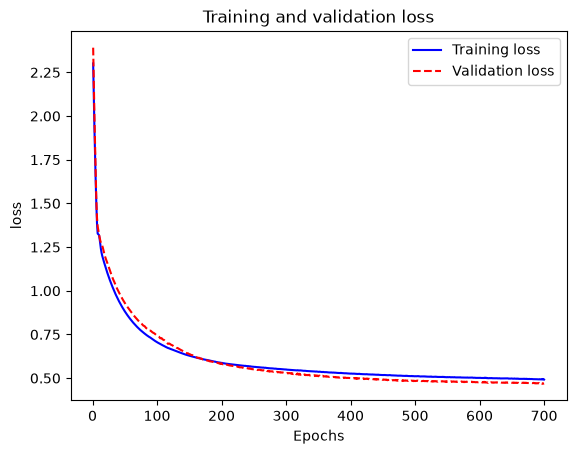

In [18]:
plot_no_dots(history.history['loss'], history.history['val_loss'], 'loss')

In [19]:
result = model.evaluate(ds_test) 
print(model.metrics_names)
print(result)

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 173ms/step - auc_1: 0.7577 - loss: 0.6368
['loss', 'compile_metrics']
[0.6367957592010498, 0.7576978206634521]


### 4.7.5. Usamos _Dropout_

In [20]:
#Indicamos la función de perdida, el algoritmo de optimización y la métrica para evaluar el rendimiento 
fn_perdida = keras.losses.BinaryCrossentropy()
optimizador = keras.optimizers.Adam(0.001)
metrica = keras.metrics.AUC()

In [21]:
tamano_entrada = 24
h0_size = 20
h1_size = 10
h2_size = 5

model =  keras.Sequential(name="german_credit_dropout")

model.add(layers.Input(shape=(tamano_entrada,)))
model.add(layers.Dropout(0.2))

model.add(layers.Dense(h0_size, activation="relu"))
model.add(layers.Dropout(0.2))
model.add(layers.Dense(h1_size, activation="relu"))
model.add(layers.Dropout(0.2))
model.add(layers.Dense(h2_size, activation="relu"))
model.add(layers.Dropout(0.2))
model.add(layers.Dense(1, activation="sigmoid"))

#Construimos el modelo y mostramos 
model.build()
print(model.summary())

Model: "german_credit_dropout"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dropout (Dropout)               │ (None, 24)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 20)             │           500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 20)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │           210 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 10)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 5)              │            55 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 5)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │             6 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 771 (3.01 KB)

 Trainable params: 771 (3.01 KB)

 Non-trainable params: 0 (0.00 B)

None


In [22]:
model.compile(loss=fn_perdida, optimizer=optimizador, metrics=[metrica])

In [23]:
num_epochs =  700
history = model.fit(ds_train, epochs=num_epochs, validation_data=ds_val)

Epoch 1/700


I0000 00:00:1793809269.277195  513323 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_271363__.18


1/4 ━━━━━━━━━━━━━━━━━━━━ 11s 4s/step - auc_2: 0.5464 - loss: 2.4161

I0000 00:00:1793809272.166121  513323 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_271363__.18


4/4 ━━━━━━━━━━━━━━━━━━━━ 7s 1s/step - auc_2: 0.4986 - loss: 2.3447 - val_auc_2: 0.4624 - val_loss: 1.7258
Epoch 2/700
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - auc_2: 0.5227 - loss: 1.9903 - val_auc_2: 0.4767 - val_loss: 1.3796
Epoch 3/700
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - auc_2: 0.5052 - loss: 1.7926 - val_auc_2: 0.5210 - val_loss: 1.0887
Epoch 4/700
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - auc_2: 0.5146 - loss: 1.6048 - val_auc_2: 0.5417 - val_loss: 0.8711
Epoch 5/700
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - auc_2: 0.5247 - loss: 1.5498 - val_auc_2: 0.5610 - val_loss: 0.7400
Epoch 6/700
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - auc_2: 0.5100 - loss: 1.3037 - val_auc_2: 0.5712 - val_loss: 0.6702
Epoch 7/700
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - auc_2: 0.4884 - loss: 1.3784 - val_auc_2: 0.5788 - val_loss: 0.6442
Epoch 8/700
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - auc_2: 0.5324 - loss: 1.0692 - val_auc_2: 0.5579 - val_loss: 0.6414
Epoch 9/700
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - au

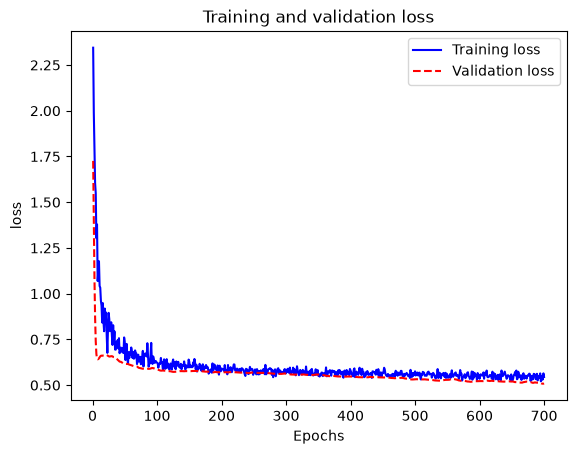

In [24]:
plot_no_dots(history.history['loss'], history.history['val_loss'], 'loss')

In [25]:
result = model.evaluate(ds_test) 
print(model.metrics_names)
print(result)

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 143ms/step - auc_2: 0.7279 - loss: 0.5831
['loss', 'compile_metrics']
[0.5830551981925964, 0.7279202342033386]
